In [ ]:
import os

print(os.listdir("/content"))

['.config', 'archive (4).zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/archive (4).zip"
extract_path = "/content/household_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
print(os.listdir(extract_path))

Extracted files:
['household_power_consumption.txt']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "/content/household_data/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (2075259, 9)

Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Data Types:
Date                      object
Time                      object
Global_active_power       object
Global_reactive_power     object
Voltage                   object
Global_intensity          object
Sub_metering_1            object
Sub_metering_2            object
Sub_metering_3           float64
dtype: object


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64


In [ ]:
print("Question marks in each column:")
print((df == "?").sum())


Question marks in each column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3               0
dtype: int64


In [ ]:
df = df.replace("?", np.nan)

print("Missing values after replacing '?':")
print(df.isnull().sum())

Missing values after replacing '?':
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [ ]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

print(df.dtypes)

Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [ ]:
# Check rows that contain any missing value
missing_rows = df[numeric_columns].isnull().any(axis=1)

print("Rows containing missing values:", missing_rows.sum())
print("Rows without missing values:", (~missing_rows).sum())


Rows containing missing values: 25979
Rows without missing values: 2049280


In [ ]:
valid = ~df[numeric_columns].isnull().any(axis=1)

# Find consecutive valid rows
groups = (~valid).cumsum()

valid_counts = valid.groupby(groups).sum()

# Find the first continuous block containing at least 10,000 valid rows
block = valid_counts[valid_counts >= 10000]

print("Number of continuous blocks with at least 10,000 valid records:",
      len(block))

print("\nFirst suitable block:")
print(block.head(1))

Number of continuous blocks with at least 10,000 valid records: 62

First suitable block:
2    12883
dtype: int64


In [ ]:
# Get the group ID of the first suitable block
first_block_id = block.index[0]

# Get all valid rows belonging to that block
valid_block = df[groups == first_block_id][numeric_columns].copy()

# Select exactly 10,000 consecutive records
data = valid_block.iloc[:10000].copy()

print("Selected data shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

print("\nFirst 5 records:")
print(data.head())

print("\nLast 5 records:")
print(data.tail())

Selected data shape: (10000, 7)

Missing values:
Global_active_power      1
Global_reactive_power    1
Voltage                  1
Global_intensity         1
Sub_metering_1           1
Sub_metering_2           1
Sub_metering_3           1
dtype: int64

First 5 records:
      Global_active_power  Global_reactive_power  Voltage  Global_intensity  \
6840                  NaN                    NaN      NaN               NaN   
6841                0.246                    0.0   241.74               1.0   
6842                0.246                    0.0   241.83               1.0   
6843                0.244                    0.0   240.96               1.0   
6844                0.244                    0.0   241.37               1.0   

      Sub_metering_1  Sub_metering_2  Sub_metering_3  
6840             NaN             NaN             NaN  
6841             0.0             0.0             0.0  
6842             0.0             0.0             0.0  
6843             0.0             0.0

In [ ]:
# Keep only rows where all numerical features are valid
valid_df = df.loc[valid, numeric_columns].copy()

# Take exactly 10,000 consecutive valid records
data = valid_df.iloc[:10000].copy()

print("Selected data shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nFirst 5 records:")
print(data.head())

Selected data shape: (10000, 7)

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

First 5 records:
   Global_active_power  Global_reactive_power  Voltage  Global_intensity  \
0                4.216                  0.418   234.84              18.4   
1                5.360                  0.436   233.63              23.0   
2                5.374                  0.498   233.29              23.0   
3                5.388                  0.502   233.74              23.0   
4                3.666                  0.528   235.68              15.8   

   Sub_metering_1  Sub_metering_2  Sub_metering_3  
0             0.0             1.0            17.0  
1             0.0             1.0            16.0  
2             0.0             2.0            17.0  
3             0.0             1.0            17.0  
4             

In [ ]:
train_size = int(len(data) * 0.8)

train_data = data.iloc[:train_size].copy()
test_data = data.iloc[train_size:].copy()

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (8000, 7)
Testing data shape: (2000, 7)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit only on training data
scaler.fit(train_data)

# Transform both training and testing data
train_scaled = scaler.transform(train_data)
test_scaled = scaler.transform(test_data)

print("Training data shape after scaling:", train_scaled.shape)
print("Testing data shape after scaling:", test_scaled.shape)

print("\nFirst 5 scaled training records:")
print(train_scaled[:5])

Training data shape after scaling: (8000, 7)
Testing data shape after scaling: (2000, 7)

First 5 scaled training records:
[[0.52602668 0.60755814 0.28828391 0.53658537 0.         0.01369863
  0.85      ]
 [0.6756474  0.63372093 0.22946038 0.67682927 0.         0.01369863
  0.8       ]
 [0.67747842 0.72383721 0.21293145 0.67682927 0.         0.02739726
  0.85      ]
 [0.67930944 0.72965116 0.23480797 0.67682927 0.         0.01369863
  0.85      ]
 [0.45409364 0.76744186 0.32912008 0.45731707 0.         0.01369863
  0.85      ]]


In [16]:
sequence_length = 60

def create_sequences(data, sequence_length):
    X = []
    y = []

    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i, 0])   # Global_active_power

    return np.array(X), np.array(y)


X_train, y_train = create_sequences(train_scaled, sequence_length)
X_test, y_test = create_sequences(test_scaled, sequence_length)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (7940, 60, 7)
y_train shape: (7940,)
X_test shape: (1940, 60, 7)
y_test shape: (1940,)


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential([
    LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        11,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,651 (45.51 KB)

 Trainable params: 11,651 (45.51 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(50),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        11,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,651 (45.51 KB)

 Trainable params: 11,651 (45.51 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - loss: 0.0048 - val_loss: 0.0014
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0036 - val_loss: 0.0013
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0034 - val_loss: 0.0011
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0032 - val_loss: 0.0010
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0030 - val_loss: 9.2713e-04
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0029 - val_loss: 0.0010
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0028 - val_loss: 8.5326e-04
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0027 - val_loss: 7.6152e-04
Epoch 9/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0026 - val_loss: 7.5379e-04
Epoch 10/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0026 - val_loss: 7.7060e-04


In [20]:
y_pred = model.predict(X_test)

print("Prediction shape:", y_pred.shape)
print("First 10 predictions:")
print(y_pred[:10].flatten())

61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Prediction shape: (1940, 1)
First 10 predictions:
[0.16231221 0.15548302 0.30281243 0.36620927 0.32435903 0.31752437
 0.33192548 0.34175682 0.33505362 0.3405021 ]


In [21]:
# Create a temporary array with the same 7 features
pred_full = np.zeros((len(y_pred), 7))
pred_full[:, 0] = y_pred.flatten()

actual_full = np.zeros((len(y_test), 7))
actual_full[:, 0] = y_test

# Convert back to original scale
y_pred_original = scaler.inverse_transform(pred_full)[:, 0]
y_test_original = scaler.inverse_transform(actual_full)[:, 0]

print("First 10 actual values:")
print(y_test_original[:10])

print("\nFirst 10 predicted values:")
print(y_pred_original[:10])

First 10 actual values:
[1.444 2.354 2.96  2.864 2.762 2.818 2.896 2.896 2.912 2.978]

First 10 predicted values:
[1.43503915 1.38282319 2.50930382 2.99403607 2.67404914 2.62179136
 2.73190223 2.80707265 2.75582    2.79747916]


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test_original, y_pred_original)
rmse = np.sqrt(mean_squared_error(y_test_original, y_pred_original))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.419188852213528
RMSE: 0.6103529034645979


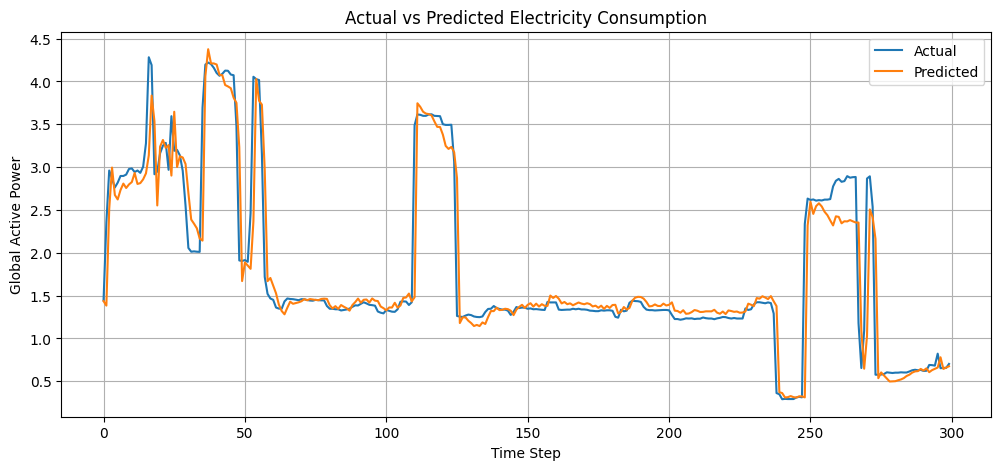

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_original[:300],
    label="Actual"
)

plt.plot(
    y_pred_original[:300],
    label="Predicted"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time Step")
plt.ylabel("Global Active Power")
plt.legend()
plt.grid(True)

plt.show()

In [24]:
comparison = pd.DataFrame({
    "Actual": y_test_original[:10],
    "Predicted": y_pred_original[:10]
})

print("Predictions on Unseen Test Records:")
print(comparison)

Predictions on Unseen Test Records:
   Actual  Predicted
0   1.444   1.435039
1   2.354   1.382823
2   2.960   2.509304
3   2.864   2.994036
4   2.762   2.674049
5   2.818   2.621791
6   2.896   2.731902
7   2.896   2.807073
8   2.912   2.755820
9   2.978   2.797479
